# **Calidad de los datos**

**Por** Ianis · **Semana 1**

Regla: el notebook solo *muestra* resultados; la lógica vive en `src/churn/` para que se pueda probar.

In [12]:
import sys; sys.path.insert(0, '../src')
import pandas as pd
from churn import config
from churn.datos import cargar_crudo

df = cargar_crudo()
df.head()

,fila_original,fallas_llamada,quejas,meses_suscripcion,nivel_cobro,segundos_uso,frecuencia_llamadas,frecuencia_sms,numeros_distintos,grupo_edad,plan_tarifa,estado,edad,valor_cliente,churn
0,1,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,2,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,3,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,4,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,5,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [13]:
print("Dimensiones de la base:", df.shape)
print("Cantidad de filas:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])

Dimensiones de la base: (3150, 15)
Cantidad de filas: 3150
Cantidad de columnas: 15


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   fila_original        3150 non-null   int64  
 1   fallas_llamada       3150 non-null   int64  
 2   quejas               3150 non-null   int64  
 3   meses_suscripcion    3150 non-null   int64  
 4   nivel_cobro          3150 non-null   int64  
 5   segundos_uso         3150 non-null   int64  
 6   frecuencia_llamadas  3150 non-null   int64  
 7   frecuencia_sms       3150 non-null   int64  
 8   numeros_distintos    3150 non-null   int64  
 9   grupo_edad           3150 non-null   int64  
 10  plan_tarifa          3150 non-null   int64  
 11  estado               3150 non-null   int64  
 12  edad                 3150 non-null   int64  
 13  valor_cliente        3150 non-null   float64
 14  churn                3150 non-null   int64  
dtypes: float64(1), int64(14)
memory usage: 369.3 KB


In [15]:
faltantes = df.isnull().sum()
tabla_faltantes = pd.DataFrame({
    "Valores faltantes": faltantes,
    "Porcentaje": (faltantes / len(df)) * 100
})
display(tabla_faltantes)

,Valores faltantes,Porcentaje
fila_original,0,0.0
fallas_llamada,0,0.0
quejas,0,0.0
meses_suscripcion,0,0.0
nivel_cobro,0,0.0
segundos_uso,0,0.0
frecuencia_llamadas,0,0.0
frecuencia_sms,0,0.0
numeros_distintos,0,0.0
grupo_edad,0,0.0


In [16]:
# Excluir fila_original porque identifica la posición del registro
columnas_comparar = df.columns.drop("fila_original")
duplicados = df.duplicated(subset=columnas_comparar).sum()
print("Registros duplicados:", duplicados)
print("Registros originales:", len(df))
print("Registros únicos:", len(df) - duplicados)

Registros duplicados: 300
Registros originales: 3150
Registros únicos: 2850


In [17]:
conteo_churn = df["churn"].value_counts().sort_index()
print("Cantidad de clientes por categoría:")
display(conteo_churn)
print("\nPorcentaje de clientes por categoría:")
display(df["churn"].value_counts(normalize=True).sort_index() * 100)

Cantidad de clientes por categoría:


churn
0    2655
1     495
Name: count, dtype: int64


Porcentaje de clientes por categoría:


churn
0    84.285714
1    15.714286
Name: proportion, dtype: float64

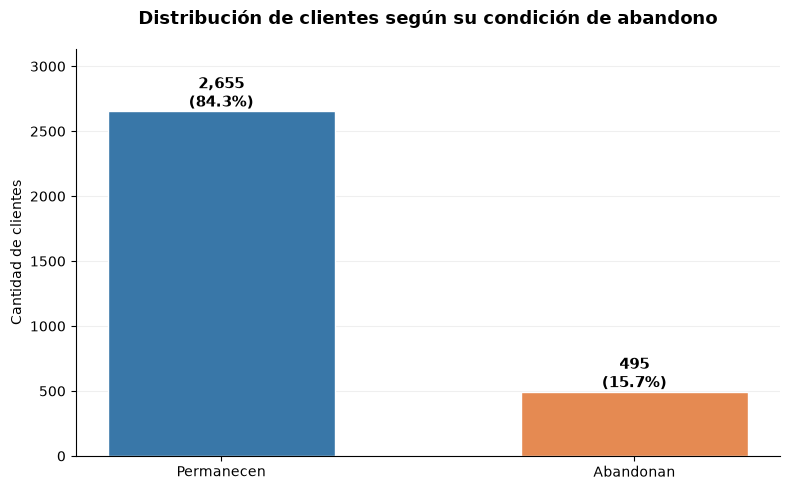

In [18]:
import matplotlib.pyplot as plt
# Datos para el gráfico
conteo_churn = df["churn"].value_counts().sort_index()
etiquetas = ["Permanecen", "Abandonan"]
valores = conteo_churn.values
porcentajes = conteo_churn.values / len(df) * 100
# Crear gráfico
fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(
    etiquetas,
    valores,
    width=0.55,
    color=["#3977A8", "#E58A52"],
    edgecolor="white"
)
# Agregar cantidades y porcentajes
for barra, cantidad, porcentaje in zip(barras, valores, porcentajes):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 35,
        f"{cantidad:,}\n({porcentaje:.1f}%)",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )
ax.set_title(
    "Distribución de clientes según su condición de abandono",
    fontsize=13,
    fontweight="bold",
    pad=18
)
ax.set_ylabel("Cantidad de clientes")
ax.set_ylim(0, max(valores) * 1.18)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

# **Base de datos limpia**

In [19]:
from churn.datos import cargar_limpio
df_limpio = cargar_limpio()
print("Dimensiones de la base procesada:", df_limpio.shape)
display(df_limpio.head())

Dimensiones de la base procesada: (2850, 14)


,fila_original,fallas_llamada,quejas,meses_suscripcion,nivel_cobro,segundos_uso,frecuencia_llamadas,frecuencia_sms,numeros_distintos,plan_tarifa,estado,edad,valor_cliente,churn
0,1,8,0,38,0,4370,71,5,17,1,1,30,197.640,0
1,2,0,0,39,0,318,5,7,4,1,2,25,46.035,0
2,3,10,0,37,0,2453,60,359,24,1,1,30,1536.520,0
3,4,10,0,38,0,4198,66,1,35,1,1,15,240.020,0
4,5,3,0,38,0,2393,58,2,33,1,1,15,145.805,0


In [20]:
columnas_limpias = df_limpio.columns.drop("fila_original")
print("Duplicados restantes:",
      df_limpio.duplicated(subset=columnas_limpias).sum())
print("Valores faltantes:",
      df_limpio.isnull().sum().sum())
print("¿Se eliminó grupo_edad?:",
      "grupo_edad" not in df_limpio.columns)
print("Total de clientes:", len(df_limpio))

Duplicados restantes: 0
Valores faltantes: 0
¿Se eliminó grupo_edad?: True
Total de clientes: 2850


# **Conclusión**
La revisión de la base de datos permitió identificar que inicialmente habían 3150 registros y 15 columnas. No se encontraron valores faltantes, pero sí se identificaron 300 registros duplicados, los cuales fueron eliminados para evitar repetir información de los clientes.

También se eliminó la variable `grupo_edad`, de acuerdo con las decisiones establecidas para el proyecto. Como resultado, se obtuvo una base procesada de 2850 registros y 14 columnas.

Finalmente, las verificaciones confirmaron que la base final no contiene registros duplicados ni valores faltantes. Esta versión será utilizada para los análisis posteriores del abandono de clientes y el cumplimiento de los objetivos.

In [22]:
from pathlib import Path
RAIZ = Path.cwd()
if not (RAIZ / "reports").exists():
    RAIZ = RAIZ.parent

print("Carpeta principal del proyecto:", RAIZ)

Carpeta principal del proyecto: c:\Users\Ianis Ramirez\OneDrive\Documentos\IANIS\UNIVERSIDAD EXTERNADO\4 SEMESTRTE\BAYESIANA\Proyecto\churn-iran


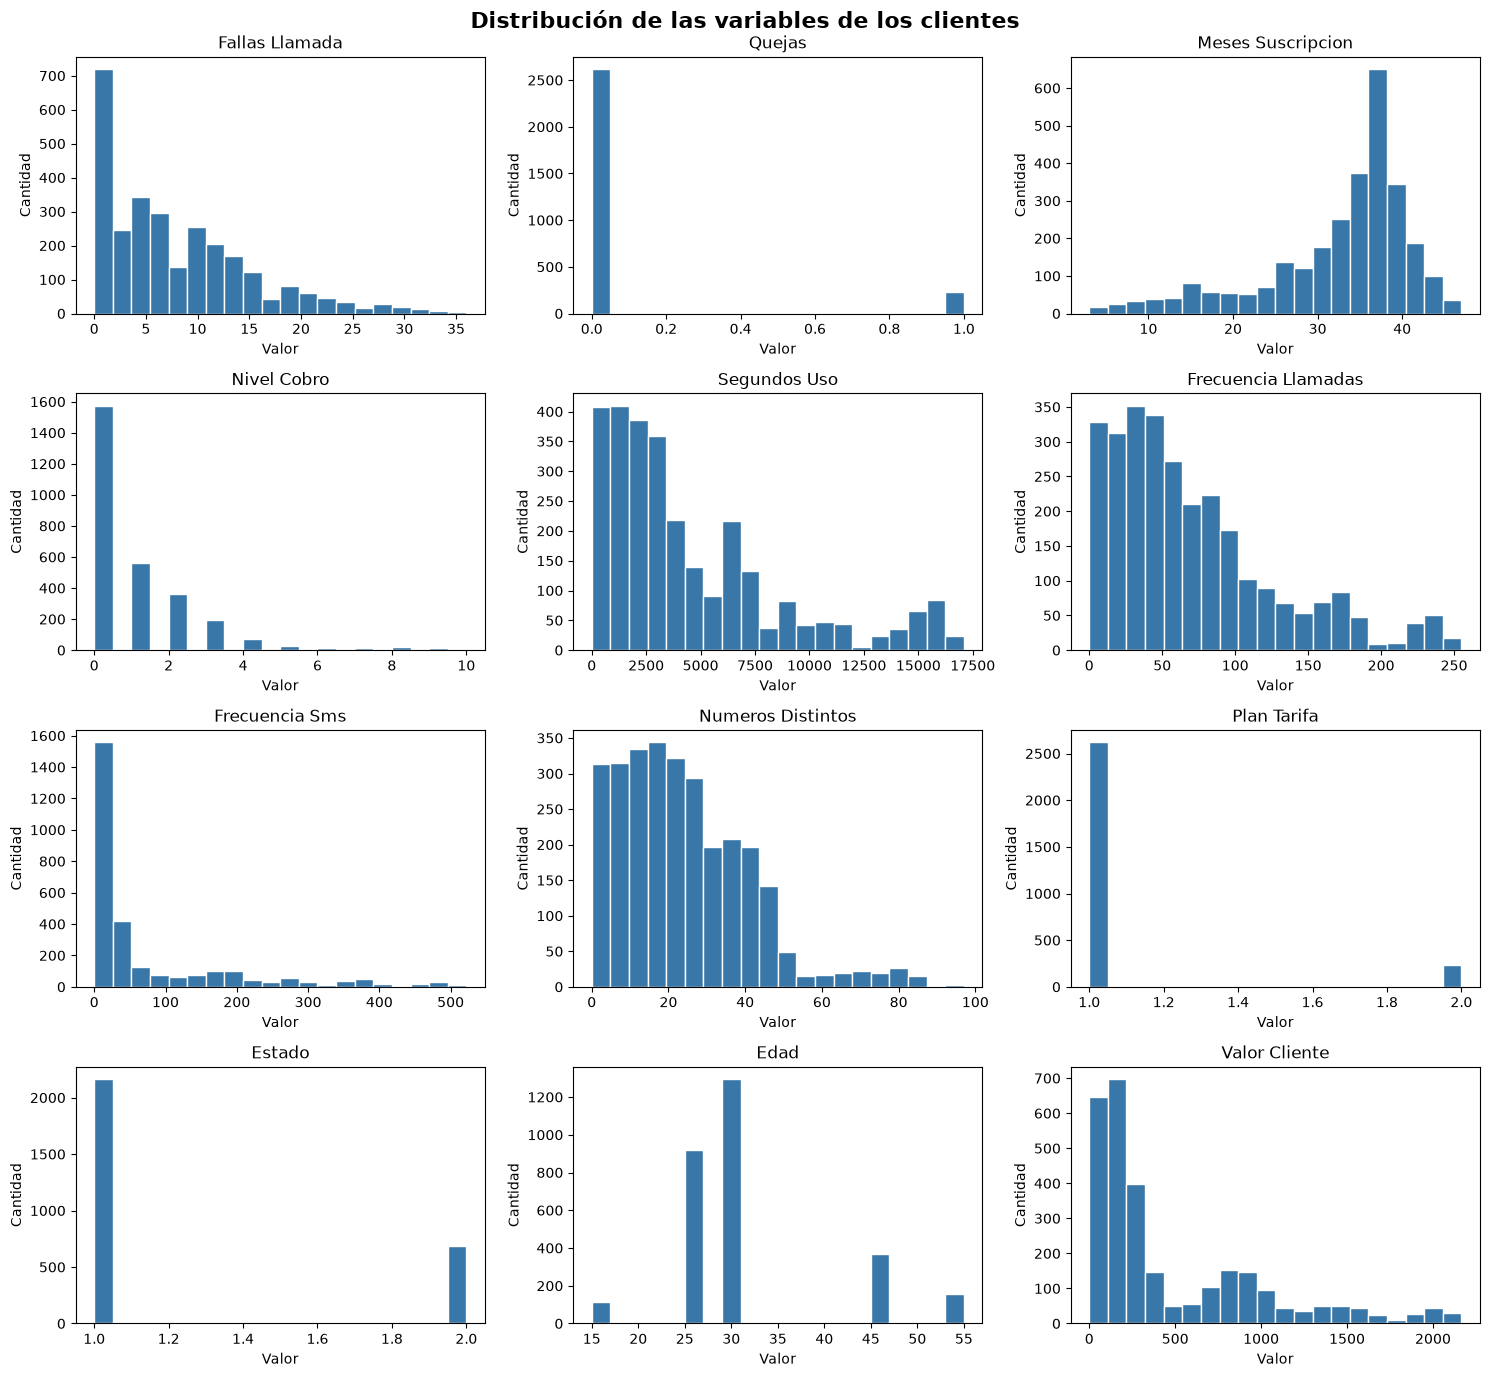

Gráfica guardada en: c:\Users\Ianis Ramirez\OneDrive\Documentos\IANIS\UNIVERSIDAD EXTERNADO\4 SEMESTRTE\BAYESIANA\Proyecto\churn-iran\reports\figures\distribuciones.png


In [23]:
# Seleccionar las variables numéricas para visualizar
columnas = [
    col for col in df_limpio.select_dtypes(include="number").columns
    if col not in ["fila_original", "churn"]
]

# Crear una cuadrícula de gráficos
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
axes = axes.flatten()

for i, columna in enumerate(columnas):
    axes[i].hist(
        df_limpio[columna],
        bins=20,
        color="#3977A8",
        edgecolor="white"
    )
    axes[i].set_title(columna.replace("_", " ").title())
    axes[i].set_ylabel("Cantidad")
    axes[i].set_xlabel("Valor")

# Ocultar espacios sobrantes
for i in range(len(columnas), len(axes)):
    axes[i].set_visible(False)

fig.suptitle(
    "Distribución de las variables de los clientes",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Guardar la imagen en reports/figures
ruta_figuras = RAIZ / "reports" / "figures"
ruta_figuras.mkdir(parents=True, exist_ok=True)

plt.savefig(
    ruta_figuras / "distribuciones.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Gráfica guardada en:", ruta_figuras / "distribuciones.png")